<a href="https://colab.research.google.com/github/shanileizer98-cyber/ml-insurance-project/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Annual Claim Cost - Car Insurance
Machine Learning final assignment.
Goal: predict annual_claim_cost for a new driver, using only fields known before the contract is signed.


## Section 2.1 - Data overview

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy.stats import norm
import sys
print(sys.version)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import KFold, GridSearchCV, cross_validate, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone
import joblib



3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [31]:
df = pd.read_csv('dataset_class.csv')
print(df.shape)
df.head()


(45000, 30)


,customer_id_hash,agent_code,country,area_type,region_density,winter_severity,driver_age,gender,marital_status,license_years,...,annual_km_estimated,pct_intercity,pct_night_driving,parking_type,current_premium,claim_count,at_fault,days_to_settlement,police_report_filed,annual_claim_cost
0,6db089eb,A043,ES,suburban,855,1.3,75,F,widowed,54,...,7500.0,5,15,lot,4450,1,0.0,27.0,0.0,6178
1,d3a860d7,A057,GB,suburban,1225,2.7,76,M,married,45,...,3000.0,25,10,street,1630,0,NaN,NaN,NaN,0
2,f0610253,A186,IL,suburban,1651,1.9,60,M,single,42,...,12500.0,0,5,garage,980,0,NaN,NaN,NaN,0
3,3137c022,A002,JP,urban,5441,7.7,55,M,divorced,34,...,10000.0,5,5,street,1810,0,NaN,NaN,NaN,0
4,a1513621,A028,FR,urban,3231,5.9,69,M,widowed,51,...,NaN,5,40,street,12290,0,NaN,NaN,NaN,0


In [32]:
df.isna().sum()

,0
customer_id_hash,0
agent_code,0
country,0
area_type,0
region_density,0
winter_severity,0
driver_age,0
gender,0
marital_status,0
license_years,0


In [33]:
y = df['annual_claim_cost']
print(y.describe())
print('share of zero:', (y == 0).mean())
print('share above 10,000:', (y > 10000).mean())


count     45000.000000
mean       3050.841644
std        7551.852703
min           0.000000
25%           0.000000
50%           0.000000
75%        3114.500000
max      224808.000000
Name: annual_claim_cost, dtype: float64
share of zero: 0.6490444444444444
share above 10,000: 0.09242222222222223


In [34]:
for col in ['gender', 'country', 'vehicle_type', 'usage_type', 'marital_status']:
    print(df[col].value_counts(), '\n')


gender
M         23624
F         20224
Male        232
m           195
female      187
male        187
f           177
Female      174
Name: count, dtype: int64 

country
US    9907
DE    5789
GB    5394
FR    4536
IT    4508
IL    4455
ES    3739
BR    3156
PL    2181
JP    1335
Name: count, dtype: int64 

vehicle_type
sedan         13916
small         12227
suv           10960
motorcycle     3072
pickup         2985
sports         1840
Name: count, dtype: int64 

usage_type
commute         18600
leisure         14265
admin_work       6226
delivery         3406
professional     2503
Name: count, dtype: int64 

marital_status
married     23290
single      13108
divorced     5550
widowed      3052
Name: count, dtype: int64 



## Data Overview-  Results and conclusions

The dataset contains **45,000 drivers** and **30 columns**.

**Key findings:**
- The target variable (`annual_claim_cost`) is highly skewed: **65% of drivers cost the company nothing**, while a small minority cost tens of thousands of shekels.
- There are missing values in `prior_claims_5y` (3,142) and `annual_km_estimated` (4,311).
- The `gender` column is recorded in several different forms (`M`, `Male`, `m`, `male`, `F`, `Female`, `f`, `female`). These will be unified to `M`/`F` in `prepare_data`.

## Section 2.2 - Data leakage

In [35]:
leak_cols = ['current_premium', 'claim_count', 'at_fault',
             'days_to_settlement', 'police_report_filed']
id_cols = ['customer_id_hash']


In [36]:
claim_cols = ['at_fault', 'days_to_settlement', 'police_report_filed']
df.groupby(df['annual_claim_cost'] > 0)[claim_cols].apply(lambda g: g.isna().mean())


,at_fault,days_to_settlement,police_report_filed
annual_claim_cost,,,
False,1.0,1.0,1.0
True,0.0,0.0,0.0


## Data Leakage-  Results and conclusions

The model needs to predict the cost at the beginning of the year, when the driver is just signing the contract. So for every column I asked: does the insurance company know this on the day of signing? If not, I can't use it.

**Columns I removed:**
- `current_premium` - this is the premium paid at the end of the year, so we don't have it at the beginning.
- `claim_count` - the number of claims in this year, which is basically the answer.
- `at_fault`, `days_to_settlement` and `police_report_filed` - they are only filled if there was a claim.
- `customer_id_hash` - not leakage, just a random ID that doesn't say anything about the driver.

I also checked the three claim columns in the code: all of them are empty for every driver that cost 0, and full for every driver that cost more. This means that just the fact that the cell is empty already tells the model the answer.

# Section 2.3 - Age-only model

In [37]:
X_age = df[['driver_age']]
age_model = LinearRegression()
age_model.fit(X_age, y)
print('b0 =', age_model.intercept_)
print('b1 =', age_model.coef_[0])
print('R2 =', age_model.score(X_age, y))


b0 = 4933.591978736083
b1 = -39.21537785620265
R2 = 0.0074425277862023576


In [38]:
ages = pd.DataFrame({'driver_age': np.arange(0, 101)})
trend = age_model.predict(ages)
avg_by_age = df.groupby('driver_age')['annual_claim_cost'].mean()


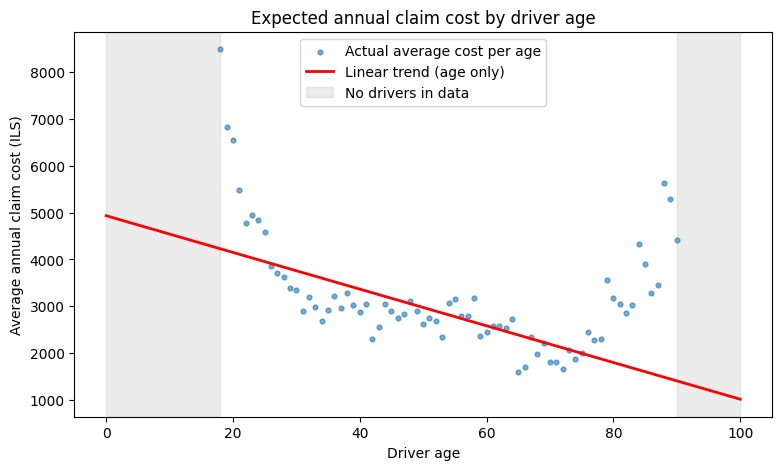

In [39]:
plt.figure(figsize=(9, 5))
plt.scatter(avg_by_age.index, avg_by_age.values, s=12, alpha=0.6,
            label='Actual average cost per age')
plt.plot(ages['driver_age'], trend, color='red', linewidth=2,
         label='Linear trend (age only)')
plt.axvspan(0, 18, color='gray', alpha=0.15, label='No drivers in data')
plt.axvspan(90, 100, color='gray', alpha=0.15)
plt.xlabel('Driver age')
plt.ylabel('Average annual claim cost (ILS)')
plt.title('Expected annual claim cost by driver age')
plt.legend()
plt.show()


## Age Model -  Results and conclusions

On average, every extra year of age lowers the expected claim cost by about 39 ILS. But the line misses the older drivers: the averages make a U shape, and after age 70 the cost goes up again. The data only has drivers aged 18-90, so outside this range the line is just a guess. Age alone explains less than 1% of the differences between drivers (R² ≈ 0.007), so we need more variables.

## Section 2.4 - Strategy by age decade

In [40]:
df['decade'] = (df['driver_age'].clip(upper=90) // 10) * 10
g = df.groupby('decade')['annual_claim_cost'].agg(['count', 'mean', 'std'])
g['p_expensive_normal'] = 1 - norm.cdf((10000 - g['mean']) / g['std'])
g['p_expensive_actual'] = df.groupby('decade')['annual_claim_cost'].apply(
    lambda s: (s > 10000).mean())
labels = {10: '18-19', 20: '20-29', 30: '30-39', 40: '40-49', 50: '50-59',
          60: '60-69', 70: '70-79', 80: '80-89', 90: '90+'}
g = g.rename(index=labels)
print(g.round(3))


        count      mean        std  p_expensive_normal  p_expensive_actual
decade                                                                    
18-19     838  7643.636  14931.620               0.437               0.203
20-29    6204  4459.165   9723.945               0.284               0.134
30-39    8187  3048.515   7313.401               0.171               0.092
40-49    9359  2828.556   6946.418               0.151               0.089
50-59    8534  2766.578   6911.631               0.148               0.081
60-69    6587  2295.988   5890.493               0.095               0.070
70-79    3892  2085.373   5683.549               0.082               0.068
80-89    1359  3503.393   8551.929               0.224               0.105
90+        40  4404.200   9834.221               0.285               0.100


In [41]:
g['p_below_zero_normal'] = norm.cdf((0 - g['mean']) / g['std'])
print(g[['mean', 'std', 'p_below_zero_normal']].round(3))
print('Actual share below 0:', (df['annual_claim_cost'] < 0).mean())


            mean        std  p_below_zero_normal
decade                                          
18-19   7643.636  14931.620                0.304
20-29   4459.165   9723.945                0.323
30-39   3048.515   7313.401                0.338
40-49   2828.556   6946.418                0.342
50-59   2766.578   6911.631                0.344
60-69   2295.988   5890.493                0.348
70-79   2085.373   5683.549                0.357
80-89   3503.393   8551.929                0.341
90+     4404.200   9834.221                0.327
Actual share below 0: 0.0


### Strategy by Age Decade- Results and conclusions

For each decade I calculated the mean and standard deviation of the claim cost, and used the normal distribution to estimate the chance that a driver is expensive (above 10,000 ILS). I also counted the real percentage of expensive drivers in each decade, to compare.

My strategy for each decade:

* 18-29: high risk. The highest chance of an expensive driver: about 20% at ages 18-19 and about 13% at ages 20-29. Strategy: a higher premium, with a discount for drivers who install a black box or take a driving course.
* 30-39: the risk goes down. About 9% expensive drivers. Strategy: a regular price, with a benefit for drivers who have years without claims.
* 40-49: low and stable risk. About 9% expensive drivers, and the biggest group in the data. Strategy: a competitive price to attract customers and keep them.
* 50-59: low risk. About 8% expensive drivers. Strategy: a competitive price and loyalty benefits, for example a discount for insuring several cars in the family.
* 60-69: very profitable. About 7% expensive drivers. Strategy: discounts and targeted marketing for this group.
* 70-79: the lowest risk. About 6.8% expensive drivers. Strategy: discounts, but start keeping track, because from age 80 the risk goes up.
* 80-89: the risk goes up again. About 10.5% expensive drivers. Strategy: check if they are fit to drive, and price by risk.
* 90+: no conclusions. There are only 40 drivers at this age, which is too few to decide on a strategy.

About the normal assumption: it's not really accurate here, because 65% of the drivers cost exactly 0, and the cost doesn't look like a bell. So the normal distribution exaggerates the chance of an expensive driver by about 2 times compared to the real numbers. But the order between the decades stays the same, so the strategy still makes sense.

I also checked how many drivers would cost less than 0 under the normal assumption (in the cell above): about 30%-36% in every decade, even though there is no such driver in the data. This shows the normal assumption doesn't fit the cost, which is mostly zeros and a few very expensive drivers.


## Section 3.1 - prepare_data (with the new features from section 4)

In [42]:
NUM_COLS = ['region_density', 'winter_severity', 'driver_age', 'license_years',
            'prior_claims_5y', 'no_claims_years', 'violations_3y', 'vehicle_age',
            'engine_hp', 'vehicle_value', 'safety_features_count', 'has_telematics',
            'annual_km_estimated', 'pct_intercity', 'pct_night_driving']
NEW_COLS = ['age_sq', 'young_driver', 'novice_driver', 'claims_per_year',
            'prior_claims_missing', 'km_missing']
CAT_COLS = ['country', 'area_type', 'gender', 'marital_status',
            'vehicle_type', 'usage_type', 'parking_type']


In [43]:
def prepare_data(df):
    df = df.copy()

    # rule 1: a column that does not exist -> create it empty
    for col in NUM_COLS + CAT_COLS:
        if col not in df.columns:
            df[col] = np.nan

    # rule 2: numbers stored as text ("22,000") -> real numbers
    for col in NUM_COLS:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=False),
                                errors='coerce')

    # rule 3: text -> lower case, no spaces
    for col in CAT_COLS:
        df[col] = df[col].astype(str).str.strip().str.lower()
        df.loc[df[col].isin(['nan', 'none', '']), col] = np.nan

    # rule 4: gender -> only 'M' or 'F'
    df['gender'] = df['gender'].str[0].str.upper()
    df.loc[~df['gender'].isin(['M', 'F']), 'gender'] = np.nan
    df['country'] = df['country'].str.upper()

    # rule 5: binary column -> only 0 or 1
    df.loc[~df['has_telematics'].isin([0, 1]), 'has_telematics'] = np.nan

    # rule 6: impossible values -> missing
    df.loc[(df['driver_age'] < 16) | (df['driver_age'] > 100), 'driver_age'] = np.nan
    df.loc[df['annual_km_estimated'] > 200000, 'annual_km_estimated'] = np.nan
    too_many = df['license_years'] > df['driver_age'] - 16
    df.loc[too_many, 'license_years'] = df['driver_age'] - 16
    for col in ['pct_intercity', 'pct_night_driving']:
        df[col] = df[col].clip(0, 100)
    df['safety_features_count'] = df['safety_features_count'].clip(0, 8)
    df['winter_severity'] = df['winter_severity'].clip(0, 10)
    for col in NUM_COLS:
        df.loc[df[col] < 0, col] = np.nan

    # ---- new features (section 4) ----
    df['age_sq'] = (df['driver_age'] - 50) ** 2
    df['young_driver'] = (df['driver_age'] < 25).astype(int)
    df['novice_driver'] = (df['license_years'] < 2).astype(int)
    df['claims_per_year'] = df['prior_claims_5y'] / (df['license_years'].clip(upper=5) + 1)
    df['prior_claims_missing'] = df['prior_claims_5y'].isna().astype(int)
    df['km_missing'] = df['annual_km_estimated'].isna().astype(int)

    return df[NUM_COLS + NEW_COLS + CAT_COLS]

In [44]:
X = prepare_data(df)
y = df['annual_claim_cost']
print(X.shape)
print(X['gender'].value_counts(dropna=False))
print(X['has_telematics'].value_counts(dropna=False))
print(X.isna().sum())
print(prepare_data(df.iloc[[5]]).shape)


(45000, 28)
gender
M    24238
F    20762
Name: count, dtype: int64
has_telematics
0.0    36367
1.0     7997
NaN      636
Name: count, dtype: int64
region_density              0
winter_severity             0
driver_age                  0
license_years               0
prior_claims_5y          3142
no_claims_years             0
violations_3y               0
vehicle_age                 0
engine_hp                   0
vehicle_value               0
safety_features_count       0
has_telematics            636
annual_km_estimated      5697
pct_intercity               0
pct_night_driving           0
age_sq                      0
young_driver                0
novice_driver               0
claims_per_year          3142
prior_claims_missing        0
km_missing                  0
country                     0
area_type                   0
gender                      0
marital_status              0
vehicle_type                0
usage_type                  0
parking_type                0
dtype: int64


## prepare_data-  Results and conclusions

The `prepare_data` function gets the raw data (all 30 columns) and always returns the same 22 columns, in the same order. The leakage columns, the ID and the target column don't come out of it. The function is built only from fixed rules that are not calculated from the data, so it is deterministic: the same input always gives the same output. I checked that it runs on the whole dataset and also on a single row, and that it doesn't need the target column.

**At this stage the function only includes the cleaning rules.** The new features are not in it yet. I will add them in Section 4, and then the number of columns will grow.

**How the function handles missing values:**
An invalid value, for example `has_telematics = 2` or 999999 km, becomes missing. The function itself does not fill in the missing values. **I will do the filling in the next part (Sections 3.2-3.3), inside the model's Pipeline:** median for numbers, and the most frequent value for text. I decided not to fill them inside `prepare_data`, because the median is calculated from the data, and if it's calculated on the whole dataset that's leakage inside the cross validation. Inside the Pipeline it will be learned in each fold only from the training data. Since the saved model will be the whole Pipeline, the filling will also happen when the model runs on the test set. Also, the function doesn't delete any rows, because every driver in the test set must get a prediction.

**How the function handles input that didn't appear in our data:**
- A different spelling, for example `"Female "`, is unified to `F`.
- A number out of range, for example age 102, becomes missing (and will be filled in the Pipeline).
- If a whole column is missing, the function creates it empty.
- A new text value, for example a country we haven't seen, will be handled in the next part, in the Pipeline, by `OneHotEncoder(handle_unknown='ignore')`: it will get 0 in all the country columns, and the model won't crash.

## Section 4 - Feature engineering

In [45]:
print(X[NEW_COLS].describe().round(2))
for col in ['young_driver', 'novice_driver', 'prior_claims_missing', 'km_missing']:
    print(col, y.groupby(X[col]).mean().round(0).to_dict())
print(y.groupby(pd.cut(X['claims_per_year'], [-0.01, 0, 0.2, 0.4, 0.6, 10]), observed=False).mean().round(0))


         age_sq  young_driver  novice_driver  claims_per_year  \
count  45000.00      45000.00       45000.00         41858.00   
mean     279.96          0.08           0.04             0.18   
std      301.33          0.27           0.19             0.25   
min        0.00          0.00           0.00             0.00   
25%       36.00          0.00           0.00             0.00   
50%      169.00          0.00           0.00             0.17   
75%      441.00          0.00           0.00             0.33   
max     1600.00          1.00           1.00             2.50   

       prior_claims_missing  km_missing  
count              45000.00    45000.00  
mean                   0.07        0.13  
std                    0.25        0.33  
min                    0.00        0.00  
25%                    0.00        0.00  
50%                    0.00        0.00  
75%                    0.00        0.00  
max                    1.00        1.00  
young_driver {0: 2813.0, 1: 5839.0}


In [46]:
print(X.groupby('novice_driver')['prior_claims_missing'].mean().round(3))
print(X.groupby('country')['prior_claims_missing'].mean().round(3))
print(X.groupby('usage_type')['km_missing'].mean().round(3))


novice_driver
0    0.045
1    0.737
Name: prior_claims_missing, dtype: float64
country
BR    0.206
DE    0.045
ES    0.082
FR    0.046
GB    0.047
IL    0.053
IT    0.080
JP    0.043
PL    0.149
US    0.049
Name: prior_claims_missing, dtype: float64
usage_type
admin_work      0.064
commute         0.095
delivery        0.459
leisure         0.047
professional    0.522
Name: km_missing, dtype: float64


### Feature engineering-  Results and conclusions

I built 6 new features inside `prepare_data`. All of them use only fields that are known on the day the policy is signed.

Two of them are complex features:
- `age_sq` = (driver_age - 50)^2. I added it so the model can learn the U-shape I saw in the decade table in section 2.4, where the mean cost goes down and then goes up again (like polynomial regression in lecture 4). I subtract 50 only to keep the numbers smaller (max 1,600 instead of 8,100). Since driver_age is also in the model, the curve the model learns is the same.
- `claims_per_year` = prior_claims_5y / (min(license_years, 5) + 1). It's the rate of past claims per year of driving. 2 claims for someone who has driven 1 year is worse than 2 claims in 5 years. I use min(license_years, 5) because prior claims are counted only for the last 5 years, and I add 1 so I don't divide by 0 (some drivers have 0 license years).

I also added:
- `young_driver` - 1 if the driver is under 25.
- `novice_driver` - 1 if the driver has had a license for less than 2 years.
- `prior_claims_missing` and `km_missing` - flags for missing data. `km_missing` also includes the 999999 values, because in `prepare_data` I turned impossible km values (above 200,000) into missing.

I chose these features based on what I saw in the data (the group averages above). For example, a novice driver costs 6,907 ₪ on average compared to 2,905 ₪, a driver who didn't report km costs 5,164 ₪ compared to 2,745 ₪, and a driver with a claim rate above 0.6 costs 8,288 ₪ compared to 1,750 ₪ for a driver with no prior claims.

I also checked who has missing data (in the cell above): prior claims are missing for 74% of novice drivers compared to 4.5% of experienced drivers, and km is missing for about half of the professional and delivery drivers. So the missing values are not random, and that's why I built flags for them.

In section 3.3 I will check with cross validation if these features really lower the RMSE, by comparing the model with and without them.


## Sections 3.2-3.3 - Pipeline, Elastic Net and 10-fold CV

In [47]:
X = prepare_data(df)
y = df['annual_claim_cost']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42)
num_cols = NUM_COLS + NEW_COLS
cat_cols = CAT_COLS

preprocessor = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore')), cat_cols),
])
cv = KFold(n_splits=10, shuffle=True, random_state=42)


In [48]:
baseline = make_pipeline(preprocessor, LinearRegression())
base_scores = cross_validate(baseline, X_train, y_train, cv=cv,
                             scoring='neg_root_mean_squared_error')
print('Baseline RMSE:', -base_scores['test_score'].mean())


Baseline RMSE: 6638.918689281292


In [49]:
def cv_rmse(num_list):
    prep = ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'),
                              StandardScaler()), num_list),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='ignore')), cat_cols),
    ])
    model = make_pipeline(prep, LinearRegression())
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring='neg_root_mean_squared_error')
    return -scores['test_score'].mean()

base_rmse = cv_rmse(NUM_COLS)
all_rmse = cv_rmse(NUM_COLS + NEW_COLS)
print('Without new features:', round(base_rmse, 1))
print('With all 6 features: ', round(all_rmse, 1))

for f in NEW_COLS:
    alone = base_rmse - cv_rmse(NUM_COLS + [f])
    others = [c for c in NEW_COLS if c != f]
    removed = cv_rmse(NUM_COLS + others) - all_rmse
    print(f, '| only this added: RMSE down by', round(alone, 1),
          '| this removed: RMSE up by', round(removed, 1))


Without new features: 6702.8
With all 6 features:  6638.9
age_sq | only this added: RMSE down by 35.6 | this removed: RMSE up by 12.7
young_driver | only this added: RMSE down by 25.3 | this removed: RMSE up by -0.2
novice_driver | only this added: RMSE down by 36.4 | this removed: RMSE up by 9.6
claims_per_year | only this added: RMSE down by 7.5 | this removed: RMSE up by 0.9
prior_claims_missing | only this added: RMSE down by 10.3 | this removed: RMSE up by 0.4
km_missing | only this added: RMSE down by 6.3 | this removed: RMSE up by 7.2


### Do the new features really help?

To check if the features from section 4 really help, I compared with 10-fold CV (on the 80% training set) a linear regression without the new features (RMSE 6,702.8) and with all of them (6,638.9). The improvement is small, about 1%, because most of the cost is luck: 65% of the drivers have no claim at all, and you can't predict an accident from the form data.

When I add each feature alone, the RMSE goes down in every case. But when all six are already in the model, removing young_driver, claims_per_year or prior_claims_missing almost doesn't change anything, because they overlap with age_sq, prior_claims_5y and novice_driver.

I kept all of them, because the difference is tiny compared to the variation between the folds, and Elastic Net can lower the weight of a feature that isn't needed.

In [50]:
en_pipe = make_pipeline(preprocessor, ElasticNet(max_iter=5000, random_state=42))
param_grid = {
    'elasticnet__alpha': [0.01, 0.1, 1, 10],
    'elasticnet__l1_ratio': [0.1, 0.5, 0.9, 1.0],
}
search = GridSearchCV(en_pipe, param_grid, cv=cv,
                      scoring='neg_root_mean_squared_error', n_jobs=-1)
search.fit(X_train, y_train)
print('Best params:', search.best_params_)
print('Best CV RMSE:', -search.best_score_)


Best params: {'elasticnet__alpha': 0.01, 'elasticnet__l1_ratio': 0.5}
Best CV RMSE: 6638.597430185153


In [51]:
for a in [0.001, 0.003, 0.01, 0.03]:
    m = make_pipeline(preprocessor, ElasticNet(alpha=a, l1_ratio=0.5,
                                               max_iter=5000, random_state=42))
    s = cross_validate(m, X_train, y_train, cv=cv,
                       scoring='neg_root_mean_squared_error', n_jobs=-1)
    print('alpha', a, '-> CV RMSE', round(-s['test_score'].mean(), 1))


alpha 0.001 -> CV RMSE 6638.9
alpha 0.003 -> CV RMSE 6638.7
alpha 0.01 -> CV RMSE 6638.6
alpha 0.03 -> CV RMSE 6639.4


### Choosing alpha and l1_ratio

Elastic Net has two parameters to choose: alpha, which sets how strong the penalty is, and l1_ratio, which sets the type of penalty.

I tested alpha with the values 0.01, 0.1, 1 and 10. Each value is 10 times bigger than the one before, because at first I didn't know if I need a weak or a strong penalty, so I wanted to cover a wide range, from almost no penalty to a very strong one. I tested l1_ratio with 0.1, 0.5, 0.9 and 1.0, to cover the whole range from almost Ridge (only makes the weights smaller) to LASSO (can set variables to 0). Together this is 16 combinations, and each one was tested with 10 folds on the training set.

The best was alpha = 0.01 and l1_ratio = 0.5, with a CV RMSE of 6,638.6. Since 0.01 was the smallest alpha in the grid, I also checked smaller and bigger values (in the cell above): 0.001 gave 6,638.9, 0.003 gave 6,638.7 and 0.03 gave 6,639.4. So 0.01 is still the best, and the differences are smaller than 1 ₪, which means the penalty almost doesn't matter here.

In [52]:
best_en = search.best_estimator_
scoring = {'rmse': 'neg_root_mean_squared_error',
           'mae': 'neg_mean_absolute_error',
           'r2': 'r2'}
res = cross_validate(best_en, X_train, y_train, cv=cv, scoring=scoring)
metrics = pd.DataFrame({'RMSE': -res['test_rmse'],
                        'MAE': -res['test_mae'],
                        'R2': res['test_r2']})
print(metrics.round(3))
print(metrics.agg(['mean', 'std', 'median']).round(3))


       RMSE       MAE     R2
0  6415.486  3678.087  0.204
1  6916.198  3765.370  0.224
2  6045.654  3636.703  0.232
3  6942.769  3904.876  0.202
4  5932.658  3695.823  0.190
5  6735.386  3760.054  0.200
6  6742.559  3769.772  0.222
7  6198.920  3644.966  0.200
8  7694.083  3768.443  0.181
9  6762.261  3770.474  0.219
            RMSE       MAE     R2
mean    6638.597  3739.457  0.207
std      517.701    79.119  0.016
median  6738.973  3762.712  0.203


In [53]:
y_pred = best_en.predict(X_test)
print('EN test RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred)), 1))
print('EN test MAE: ', round(mean_absolute_error(y_test, y_pred), 1))
print('EN test R2:  ', round(r2_score(y_test, y_pred), 3))

base_pred = baseline.fit(X_train, y_train).predict(X_test)
base_rmse = np.sqrt(mean_squared_error(y_test, base_pred))
print('Baseline test RMSE:', round(base_rmse, 1))
const_pred = np.full(len(y_test), y_train.mean())
const_rmse_test = np.sqrt(mean_squared_error(y_test, const_pred))
print('Constant test RMSE:', round(const_rmse_test, 1))
const_rmse_train = np.sqrt(((y_train - y_train.mean()) ** 2).mean())
print('Constant train RMSE:', round(const_rmse_train, 1))


EN test RMSE: 6977.6
EN test MAE:  3864.0
EN test R2:   0.209
Baseline test RMSE: 6976.9
Constant test RMSE: 7848.0
Constant train RMSE: 7476.0


In [54]:
errors = y_test - y_pred
print('Median absolute error:', round(np.median(np.abs(errors)), 1))

sq = np.sort(errors ** 2)[::-1]
top1 = int(len(sq) * 0.01)
print('Share of squared error from the top 1% drivers:', round(sq[:top1].sum() / sq.sum(), 2))

print('Total predicted (millions):', round(y_pred.sum() / 1e6, 1))
print('Total actual (millions):   ', round(y_test.sum() / 1e6, 1))

groups = pd.qcut(y_pred, 5, labels=['1 cheapest', '2', '3', '4', '5 most expensive'])
table = pd.DataFrame({'predicted': y_pred, 'actual': y_test.values})
print(table.groupby(groups, observed=False).mean().round(0))


Median absolute error: 2394.5
Share of squared error from the top 1% drivers: 0.48
Total predicted (millions): 27.6
Total actual (millions):    28.6
                  predicted  actual
1 cheapest           -918.0   548.0
2                     839.0  1092.0
3                    2416.0  1915.0
4                    4447.0  3286.0
5 most expensive     8527.0  9036.0


### How big are the errors?

An RMSE of about 7,000 ₪ looks very big, because the average driver costs about 3,050 ₪. But the cost is extreme: 65% of the drivers cost 0, and a few cost tens of thousands (the maximum is 224,808 ₪). RMSE squares every error, so a few very expensive drivers take most of it. In the cell above, the top 1% of drivers are responsible for about half of all the squared error, and the median error is only about 2,400 ₪.

The model can't predict a single driver well, because a big accident is mostly luck. But it ranks groups of drivers well: the 20% that the model thought are the most expensive really cost about 9,000 ₪ on average, and the 20% it thought are the cheapest cost about 550 ₪. The total is also close: 27.6 million predicted compared to 28.6 million actual. This is what an insurance company needs, because it prices groups and not single drivers.

A limitation: for the cheapest group the model predicts a negative cost on average (-918 ₪), because a linear model doesn't know that a cost can't be below 0.


### Sections 3.2-3.3 - Summary

I split the drivers into 80% training and 20% test, and I didn't touch the test set until the end. I built a Pipeline where filling missing values (median for numbers, most frequent value for words), scaling and One-Hot all happen inside the cross validation, so in every fold they are learned only from the training data.

The baseline model, a regular linear regression, got an RMSE of 6,639 in CV. For Elastic Net I chose alpha and l1_ratio with GridSearchCV and 10-fold CV, and the chosen values were alpha = 0.01 and l1_ratio = 0.5.

The results over the 10 folds: mean RMSE 6,639 (std 518), mean MAE 3,739 (std 79), and mean R² 0.207 (std 0.016). On the test set, once at the end: RMSE 6,978, MAE 3,864 and R² 0.209. The RMSE on the test set is higher, but the constant prediction is also higher there (7,848 compared to 7,476 on the training set), which means the test set happened to get more expensive drivers. The improvement over the constant prediction is similar in both, about 11%.

Elastic Net is almost the same as the regular linear regression on the same features, because alpha is very small: there are 36,000 drivers in the training set, so there isn't much risk of memorizing. The improvement over a simple regression without the new features (6,703, in the feature check above) comes mostly from the features.

As a central measure I chose the median for RMSE, because it jumps between folds because of very expensive drivers, and the mean for MAE and R², because they are stable.

## Section 3.4 - What the model says about driver age

In [55]:
names = best_en[0].get_feature_names_out()
coefs = pd.Series(best_en[-1].coef_, index=names)
print(coefs[['num__driver_age', 'num__age_sq', 'num__young_driver']].round(1))
top10 = coefs.abs().sort_values(ascending=False).head(10).index
print(coefs[top10].round(1))


num__driver_age     -203.3
num__age_sq          548.9
num__young_driver    107.9
dtype: float64
cat__country_US                 2418.6
num__vehicle_value              1495.2
cat__usage_type_professional    1019.5
cat__vehicle_type_motorcycle     854.2
cat__country_PL                 -851.3
cat__usage_type_leisure         -743.9
num__engine_hp                   690.1
cat__country_BR                 -664.0
num__claims_per_year             662.2
cat__area_type_rural             604.0
dtype: float64


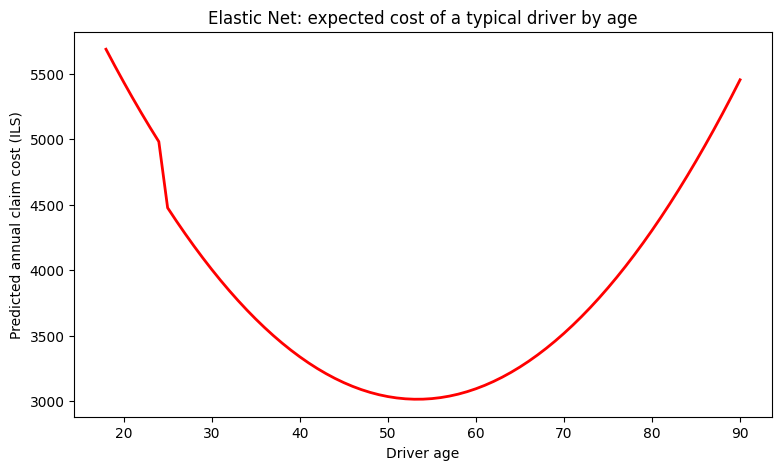

In [56]:
typical = X_train.iloc[[0]].copy()
for col in num_cols:
    typical[col] = X_train[col].median()
for col in cat_cols:
    typical[col] = X_train[col].mode()[0]

ages = np.arange(18, 91)
rows = pd.concat([typical] * len(ages), ignore_index=True)
rows['driver_age'] = ages
rows['age_sq'] = (ages - 50) ** 2
rows['young_driver'] = (ages < 25).astype(int)
pred = best_en.predict(rows)

plt.figure(figsize=(9, 5))
plt.plot(ages, pred, color='red', linewidth=2)
plt.xlabel('Driver age')
plt.ylabel('Predicted annual claim cost (ILS)')
plt.title('Elastic Net: expected cost of a typical driver by age')
plt.show()


In [57]:
print(pd.Series(pred, index=ages).loc[[18, 24, 25, 30, 40, 53, 60, 70, 80, 90]].round(0))
print('Cheapest age:', ages[pred.argmin()], '-> cost', round(pred.min()))


18    5689.0
24    4983.0
25    4477.0
30    4007.0
40    3339.0
53    3015.0
60    3095.0
70    3518.0
80    4305.0
90    5455.0
dtype: float64
Cheapest age: 53 -> cost 3015


### What the model says about driver age

According to the model, when all the other details of the driver are the same, the expected cost goes down with age until the mid-50s and then goes up again: a U-shape. A typical driver aged 18 is expected to cost about 5,689 ₪ a year, at 30 about 4,007, and at 53 the cost is the lowest, about 3,015. After that it goes up again: at 70 about 3,518, at 80 about 4,305 and at 90 about 5,455.

There is also a step at age 25 in the graph: from 4,983 to 4,477 ₪, because the feature young_driver changes from 1 to 0.

I can't read each age coefficient alone, because age enters the model in three columns that move together. That's why I showed the prediction for a typical driver at every age. The coefficient of driver_age is negative (-203) and the coefficient of age_sq is positive (549), and this is what creates the U-shape. Unlike the straight line from section 2.3, here the model sees both ends.

Age is not the strongest factor: country, vehicle value, usage type and the past claim rate have a bigger effect.